# Tín hiệu hình sin, hệ LTI và đáp ứng tần số

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dangquanghieu/tinhieu-hethong-notebooks/blob/main/notebooks/05_tin-hieu-hinh-sin-va-dap-ung-tan-so.ipynb)

Notebook minh họa tín hiệu hình sin (sinusoidal signal) liên tục và rời rạc, ý nghĩa của tần số cao/thấp, rồi dùng hàm riêng (eigenfunction) để đi từ hệ thống tuyến tính bất biến theo thời gian (LTI) đến đáp ứng tần số (frequency response).

## Mục tiêu

- Phân biệt tần số $f$, tần số góc liên tục $\Omega$ và tần số góc rời rạc $\omega$.
- Nhận biết tín hiệu tần số thấp và cao trong trường hợp liên tục và rời rạc.
- Giải thích vì sao tần số rời rạc chỉ cần xét trong một chu kỳ dài $2\pi$.
- Kiểm chứng hàm mũ phức là hàm riêng của hệ LTI rời rạc.
- Đọc đáp ứng biên độ và đáp ứng pha của bộ lọc trung bình trượt.

## Tóm tắt lý thuyết

Tín hiệu hình sin liên tục và rời rạc có dạng

$$
x(t) = A\cos(\Omega_0t + \phi), \qquad
x[n] = A\cos(\omega_0n + \phi).
$$

Trong đó $\Omega_0$ có đơn vị rad/s, $f_0 = \Omega_0/(2\pi)$ có đơn vị Hz, còn $\omega_0$ có đơn vị rad/mẫu. Nếu $x[n]$ là các mẫu của $x(t)$ với chu kỳ lấy mẫu $T_s$, thì

$$
\omega_0 = \Omega_0T_s = 2\pi\frac{f_0}{f_s}, \qquad f_s = \frac{1}{T_s}.
$$

Với dãy rời rạc, các tần số sai khác một bội nguyên của $2\pi$ cho cùng một dãy:

$$
\cos(\omega_0n) = \cos((\omega_0 + 2\pi k)n), \qquad k\in\mathbb{Z}.
$$

Xét hệ LTI rời rạc có đáp ứng xung $h[n]$. Khi đầu vào là $e^{j\omega_0n}$, đầu ra là

$$
y[n] = H(e^{j\omega_0})e^{j\omega_0n}, \qquad
H(e^{j\omega}) := \sum_{k=-\infty}^{\infty}h[k]e^{-j\omega k}.
$$

Do đó hệ không tạo tần số mới; $\left|H(e^{j\omega})\right|$ cho biết thay đổi biên độ, còn $\arg\{H(e^{j\omega})\}$ cho biết thay đổi pha.

**Xem thêm:** Chương 1, *Tín hiệu hình sin*; Chương 2, *Đáp ứng xung và phép chập cho hệ thống rời rạc*; Chương 3, *Hàm riêng của hệ thống LTI và đáp ứng tần số* trong [giáo trình](https://github.com/dangquanghieu/book-thht).

## Bản đồ Python của notebook

Sinh viên chỉ cần chạy và đọc mã. Các mảng giá trị luôn đi kèm một trục thời gian hoặc chỉ số; vị trí trong mảng Python không tự mang ý nghĩa $t$, $n$ hoặc $k$.

| Ý tưởng Python | Vai trò trong minh họa | Liên hệ với tín hiệu |
|---|---|---|
| `np.linspace`, `np.arange` | tạo trục $t$, $n$, $\omega$ | thời điểm, chỉ số mẫu, tần số |
| `np.cos`, `np.exp` | tính hàm sin và hàm mũ phức | tín hiệu và hàm riêng |
| `np.sum(..., axis=0)` | cộng theo chỉ số $k$ | tổng chập hữu hạn |
| `plot`, `stem` | vẽ liên tục và rời rạc | phân biệt $x(t)$ và $x[n]$ |

### Khởi tạo: chỉ cần chạy

Cell này nạp NumPy và Matplotlib, định dạng hình, rồi định nghĩa hai hàm vẽ dùng chung. Không cần phân tích chi tiết mã hạ tầng này.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "lines.linewidth": 2.0,
})


def stem_sequence(ax, n, x, label=None, color="C0"):
    """Draw a discrete-time sequence x[n] on its explicit index axis."""
    markerline, stemlines, _ = ax.stem(n, x, basefmt=" ", label=label)
    plt.setp(markerline, color=color)
    plt.setp(stemlines, color=color)
    ax.axhline(0, color="0.25", linewidth=0.8)
    ax.set_xlabel("Chỉ số $n$")
    ax.set_ylabel("Biên độ")
    if label is not None:
        ax.legend()


def frequency_response(h, k, omega):
    """Evaluate the frequency response from finite samples h[k]."""
    return np.sum(h[:, None] * np.exp(-1j * k[:, None] * omega), axis=0)

## Minh họa 1: Tần số liên tục và các mẫu rời rạc

Ta quan sát hai tín hiệu hình sin liên tục có cùng biên độ và pha. Tín hiệu có tần số lớn hơn hoàn thành nhiều chu kỳ hơn trong cùng khoảng thời gian. Các điểm tròn biểu diễn những mẫu cách nhau $T_s$ giây; chúng tạo thành dãy $x[n] = x(nT_s)$.

**Python cần biết:** `np.linspace(a, b, N)` tạo $N$ điểm cách đều từ $a$ đến $b$, phù hợp để xấp xỉ một trục thời gian liên tục. `np.arange(N)` tạo các chỉ số nguyên $0,1,\ldots,N-1$. Với mảng `t`, biểu thức `np.cos(2 * np.pi * f * t)` tính giá trị tại mọi thời điểm trong `t`.

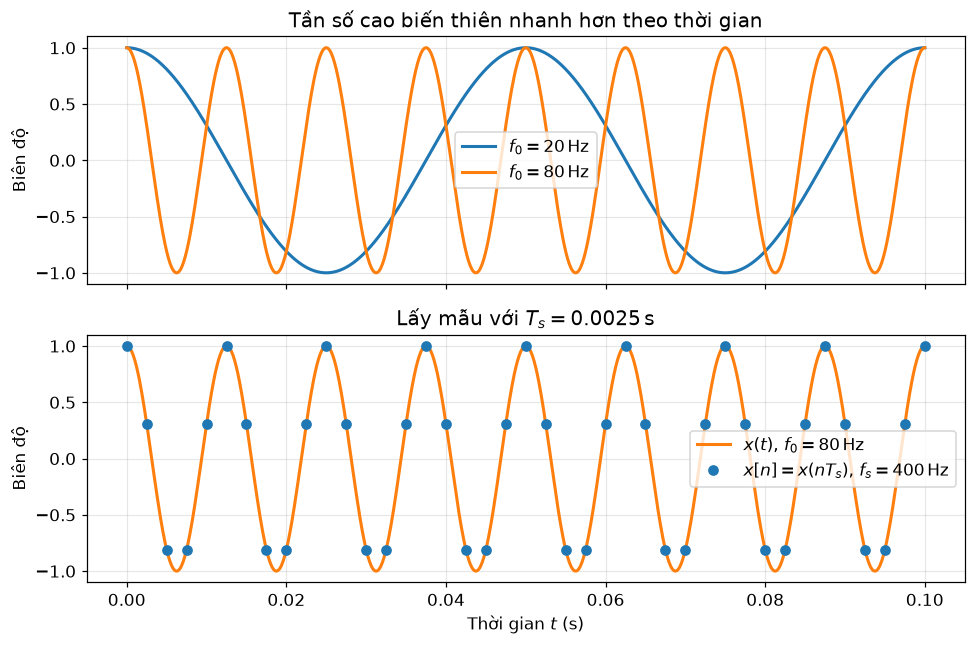

Với $f_0=80\,\mathrm{Hz}$: $\Omega_0=502.7\,\mathrm{rad/s}$, $\omega_0=1.26\,\mathrm{rad/mẫu}$.


In [2]:
# Tạo tín hiệu liên tục và các mẫu của tín hiệu.
t = np.linspace(0, 0.10, 1_000)
f_low, f_high = 20.0, 80.0
x_low = np.cos(2 * np.pi * f_low * t)
x_high = np.cos(2 * np.pi * f_high * t)

fs = 400.0
Ts = 1 / fs
n = np.arange(0, 41)
t_samples = n * Ts
x_samples = np.cos(2 * np.pi * f_high * t_samples)

# Vẽ dạng sóng liên tục và các mẫu rời rạc.
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(t, x_low, label=rf"$f_0 = {f_low:.0f}\,\mathrm{{Hz}}$")
axes[0].plot(t, x_high, label=rf"$f_0 = {f_high:.0f}\,\mathrm{{Hz}}$")
axes[0].set_ylabel("Biên độ")
axes[0].set_title("Tần số cao biến thiên nhanh hơn theo thời gian")
axes[0].legend()

axes[1].plot(t, x_high, color="C1", label=r"$x(t)$, $f_0=80\,\mathrm{Hz}$")
axes[1].plot(t_samples, x_samples, "o", color="C0", label=rf"$x[n]=x(nT_s)$, $f_s={fs:.0f}\,\mathrm{{Hz}}$")
axes[1].set_xlabel("Thời gian $t$ (s)")
axes[1].set_ylabel("Biên độ")
axes[1].set_title(rf"Lấy mẫu với $T_s={Ts:.4f}\,\mathrm{{s}}$")
axes[1].legend()
fig.tight_layout()
plt.show()

print(rf"Với $f_0={f_high:.0f}\,\mathrm{{Hz}}$: $\Omega_0={2 * np.pi * f_high:.1f}\,\mathrm{{rad/s}}$, "
      rf"$\omega_0={2 * np.pi * f_high / fs:.2f}\,\mathrm{{rad/mẫu}}$.")

**Nhận xét:** Với tín hiệu liên tục, $f_0$ hoặc $\Omega_0$ càng lớn thì tín hiệu đổi giá trị càng nhanh. Sau khi lấy mẫu, cùng một tần số vật lý được biểu diễn bằng $\omega_0 = 2\pi f_0/f_s$. Vì vậy $\omega_0$ không có đơn vị Hz và chỉ có ý nghĩa khi biết $f_s$.

## Minh họa 2: Tần số cao và thấp của dãy rời rạc

Trong một chu kỳ cơ bản $0\leq\omega\leq2\pi$, tần số cao nhất nằm gần $\pi$, nơi các mẫu thay đổi gần như trái dấu ở mỗi bước chỉ số. Khi $\omega$ đi xa $\pi$ theo cả hai phía, tín hiệu thay đổi chậm hơn và có tần số thấp hơn. Hình sau đi từ gần $0$ đến gần $2\pi$ để quan sát đầy đủ quy luật này.

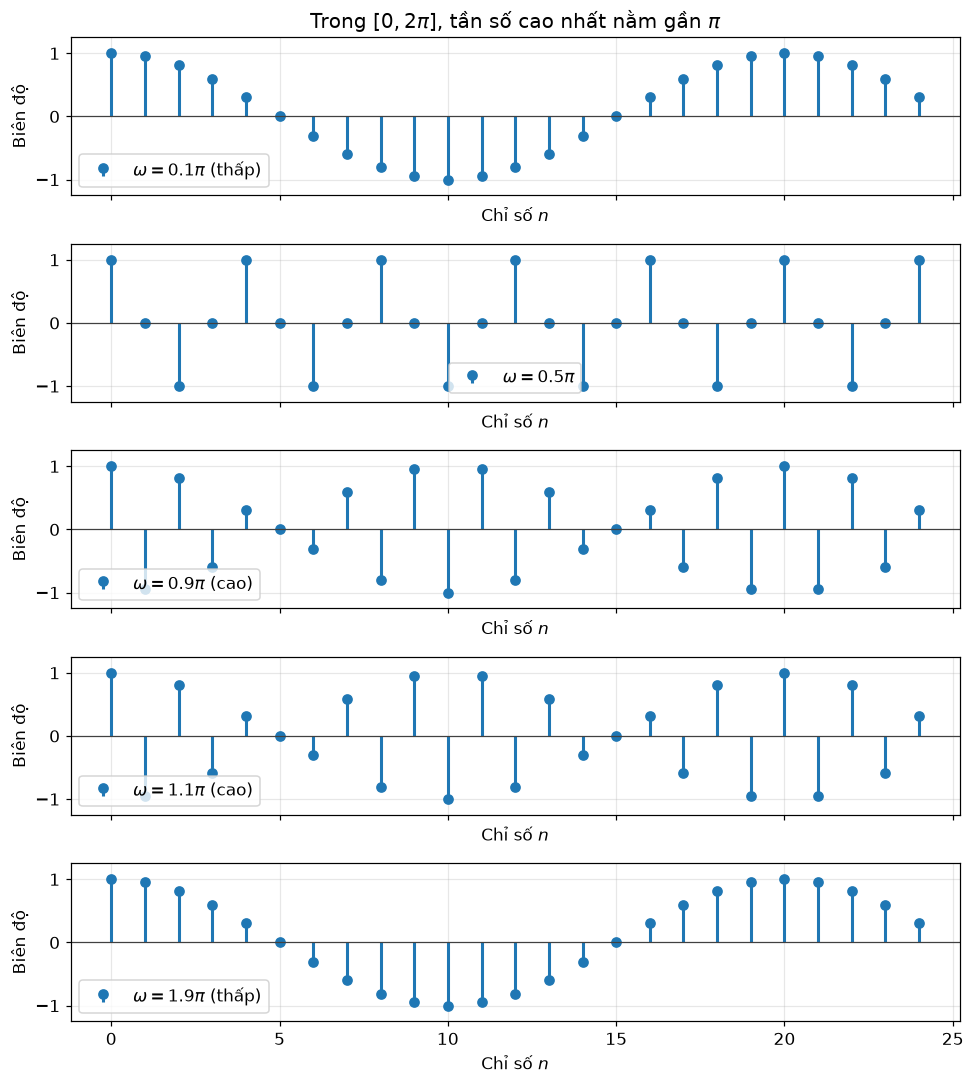

In [3]:
# Tạo ba dãy cùng biên độ trên cùng trục chỉ số n.
n = np.arange(0, 25)
omegas = [0.1 * np.pi, 0.5 * np.pi, 0.9 * np.pi, 1.1 * np.pi, 1.9 * np.pi]
labels = [
    r"$\omega=0.1\pi$ (thấp)", r"$\omega=0.5\pi$", r"$\omega=0.9\pi$ (cao)",
    r"$\omega=1.1\pi$ (cao)", r"$\omega=1.9\pi$ (thấp)",
]

# Vẽ bằng stem vì đây là tín hiệu rời rạc.
fig, axes = plt.subplots(5, 1, figsize=(9, 10), sharex=True)
for ax, omega, label in zip(axes, omegas, labels):
    stem_sequence(ax, n, np.cos(omega * n), label=label)
    ax.set_ylim(-1.25, 1.25)
axes[0].set_title(r"Trong $[0, 2\pi]$, tần số cao nhất nằm gần $\pi$")
fig.tight_layout()
plt.show()

**Nhận xét:** Không thể xếp thứ tự cao/thấp theo giá trị số của $\omega$ trên toàn trục thực. Ta quy về một chu kỳ, thường là $[-\pi,\pi)$ hoặc $[0,2\pi)$. Trong khoảng $[0,2\pi]$, tần số tăng khi $\omega$ tiến về $\pi$ và giảm khi $\omega$ đi xa $\pi$ về phía $0$ hoặc $2\pi$.

## Minh họa 3: Hàm mũ phức là hàm riêng của hệ LTI

Theo notebook về phép chập, đầu ra của hệ LTI là $y[n]=x[n]*h[n]$. Áp dụng tính giao hoán của phép chập, ta viết $y[n]=h[n]*x[n]=\sum_k h[k]x[n-k]$. Nếu $x[n]=e^{j\omega_0n}$, thay vào tổng chập rồi đặt $e^{j\omega_0n}$ ra ngoài tổng sẽ thu được

$$
y[n] = \left(\sum_k h[k]e^{-j\omega_0k}\right)e^{j\omega_0n}
= H(e^{j\omega_0})e^{j\omega_0n}.
$$

Vì đầu ra chỉ là đầu vào nhân với một hằng số phức, $e^{j\omega_0n}$ là hàm riêng. Ta kiểm chứng điều này với bộ lọc trung bình trượt năm mẫu.

**Python cần biết:** `1j` là đơn vị ảo $j$ trong Python. Mảng `h[:, None]` có kích thước $(M,1)$, còn `np.exp(...)` có kích thước $(M,N)$. Phép nhân dùng broadcasting để mỗi hệ số $h[k]$ nhân với toàn bộ các mẫu ứng với chỉ số đó; `axis=0` cộng theo $k$. Đây là bản dịch vector hóa của tổng chập.

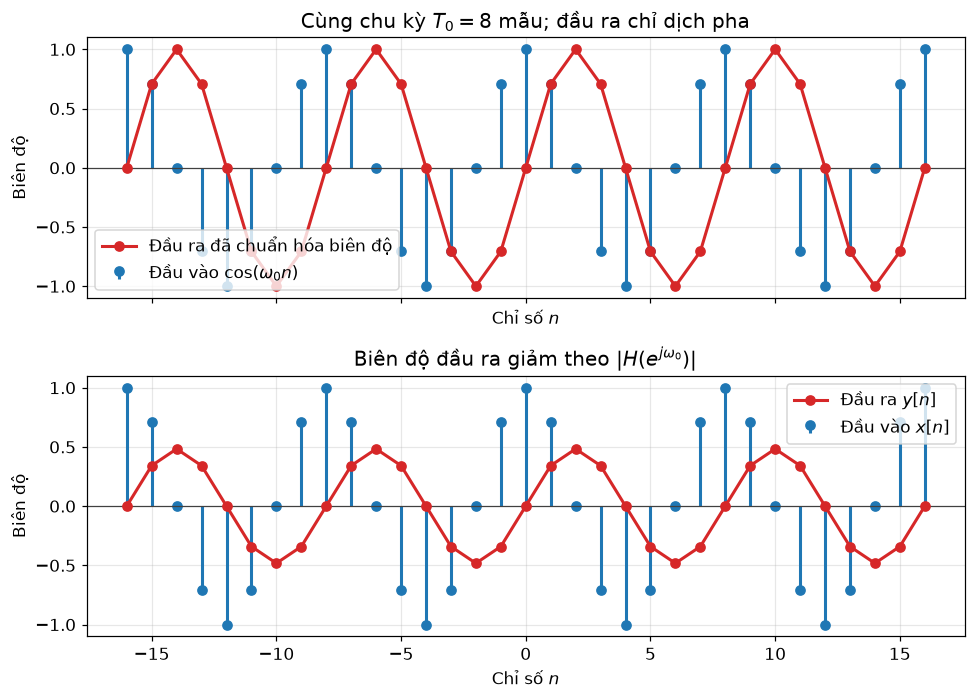

H(e^{jω₀}) = 0.000-0.483j
|H(e^{jω₀})| = 0.483
∠H(e^{jω₀}) = -1.571 rad


In [4]:
# Tạo đáp ứng xung h[k] và đầu vào phức xác định trên mọi chỉ số hiển thị.
k = np.arange(0, 5)
h = np.ones_like(k, dtype=float) / len(k)
omega_0 = 0.25 * np.pi
n = np.arange(-16, 17)
x = np.exp(1j * omega_0 * n)

# Tính đầu ra theo tổng chập và theo dạng hàm riêng.
y_from_sum = np.sum(h[:, None] * np.exp(1j * omega_0 * (n[None, :] - k[:, None])), axis=0)
H_at_omega_0 = frequency_response(h, k, np.array([omega_0]))[0]
y_from_eigenfunction = H_at_omega_0 * x
assert np.allclose(y_from_sum, y_from_eigenfunction)

# Vẽ phần thực để tách riêng ảnh hưởng của pha và biên độ.
x_real = np.real(x)
y_real = np.real(y_from_eigenfunction)
y_normalized = y_real / abs(H_at_omega_0)

fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
stem_sequence(axes[0], n, x_real, label=r"Đầu vào $\cos(\omega_0n)$", color="C0")
axes[0].plot(n, y_normalized, "o-", color="C3", label=r"Đầu ra đã chuẩn hóa biên độ")
axes[0].set_title(r"Cùng chu kỳ $T_0=8$ mẫu; đầu ra chỉ dịch pha")
axes[0].legend()

stem_sequence(axes[1], n, x_real, label=r"Đầu vào $x[n]$", color="C0")
axes[1].plot(n, y_real, "o-", color="C3", label=r"Đầu ra $y[n]$")
axes[1].set_title(r"Biên độ đầu ra giảm theo $|H(e^{j\omega_0})|$")
axes[1].legend()
fig.tight_layout()
plt.show()

print(f"H(e^{{jω₀}}) = {H_at_omega_0:.3f}")
print(f"|H(e^{{jω₀}})| = {abs(H_at_omega_0):.3f}")
print(f"∠H(e^{{jω₀}}) = {np.angle(H_at_omega_0):.3f} rad")

**Nhận xét:** Ở hình trên, đồ thị thứ nhất đã chuẩn hóa biên độ đầu ra để chỉ còn khác biệt pha: khoảng lặp của cả hai dãy đều là $T_0=8$ mẫu. Đồ thị thứ hai giữ biên độ thực, cho thấy đầu ra đồng thời bị suy giảm. Với tín hiệu hình sin thực $A\cos(\omega_0n+\phi)$, kết quả được diễn giải là

$$
y[n] = A\lvert H(e^{j\omega_0})\rvert
\cos\left(\omega_0n+\phi+\angle H(e^{j\omega_0})\right).
$$

Vì vậy, đáp ứng tần số là cách mô tả hệ LTI theo từng thành phần hình sin.

## Minh họa 4: Đáp ứng tần số của bộ lọc trung bình trượt

Bộ lọc năm mẫu đang xét có

$$
h[n] = \frac{1}{5}\operatorname{rect}_5[n].
$$

Ta quét $\omega$ từ $0$ đến $\pi$, tính trực tiếp tổng hữu hạn định nghĩa $H(e^{j\omega})$, rồi đặt ba tần số đã khảo sát lên đồ thị. Không dùng FFT trong notebook này.

Bộ lọc này có các điểm triệt, tức là những tần số làm $|H(e^{j\omega})|=0$. Tại điểm triệt, pha không xác định. Đồ thị bên dưới dùng pha chính $\arg\{H(e^{j\omega})\}\in[-\pi,\pi)$ và để trống một lân cận nhỏ quanh các điểm triệt.

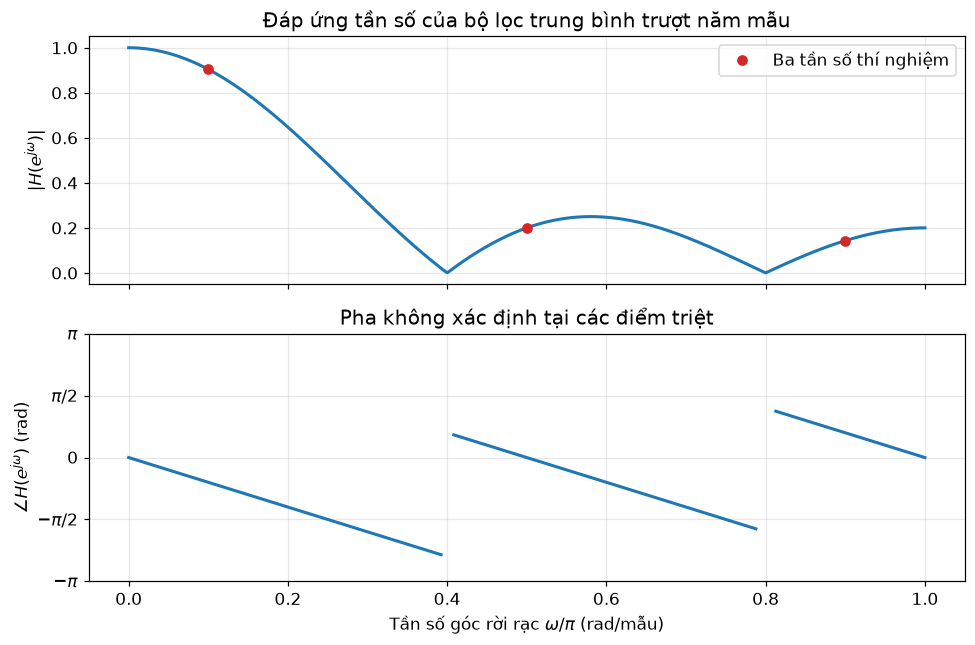

ω = 0.1π: |H| = 0.904, ∠H = -0.628 rad
ω = 0.5π: |H| = 0.200, ∠H = 0.000 rad
ω = 0.9π: |H| = 0.143, ∠H = 0.628 rad


In [5]:
# Tính đáp ứng tần số trên một lưới tần số rời rạc.
omega = np.linspace(0, np.pi, 1_000)
H = frequency_response(h, k, omega)
magnitude = np.abs(H)
phase = np.angle(H)
phase[magnitude < 0.02] = np.nan  # Pha không xác định gần các điểm triệt.
test_omegas = np.array([0.1 * np.pi, 0.5 * np.pi, 0.9 * np.pi])
H_test = frequency_response(h, k, test_omegas)

# Vẽ đáp ứng biên độ và đáp ứng pha.
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(omega / np.pi, magnitude)
axes[0].plot(test_omegas / np.pi, np.abs(H_test), "o", color="C3", label="Ba tần số thí nghiệm")
axes[0].set_ylabel(r"$|H(e^{j\omega})|$")
axes[0].set_title("Đáp ứng tần số của bộ lọc trung bình trượt năm mẫu")
axes[0].legend()

axes[1].plot(omega / np.pi, phase)
axes[1].set_xlabel(r"Tần số góc rời rạc $\omega/\pi$ (rad/mẫu)")
axes[1].set_ylabel(r"$\angle H(e^{j\omega})$ (rad)")
axes[1].set_title("Pha không xác định tại các điểm triệt")
axes[1].set_ylim(-np.pi, np.pi)
axes[1].set_yticks(
    [-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi],
    [r"$-\pi$", r"$-\pi/2$", r"$0$", r"$\pi/2$", r"$\pi$"],
)
fig.tight_layout()
plt.show()

for omega_value, response in zip(test_omegas, H_test):
    print(f"ω = {omega_value / np.pi:.1f}π: |H| = {abs(response):.3f}, ∠H = {np.angle(response):.3f} rad")

Đồ thị đáp ứng dự đoán trực tiếp đầu ra của từng tín hiệu hình sin. Hình dưới so sánh ba đầu vào và đầu ra tương ứng. Ta tính đầu ra từ công thức hàm riêng để xem phần trạng thái xác lập; không có ảnh hưởng biên của một đoạn tín hiệu hữu hạn.

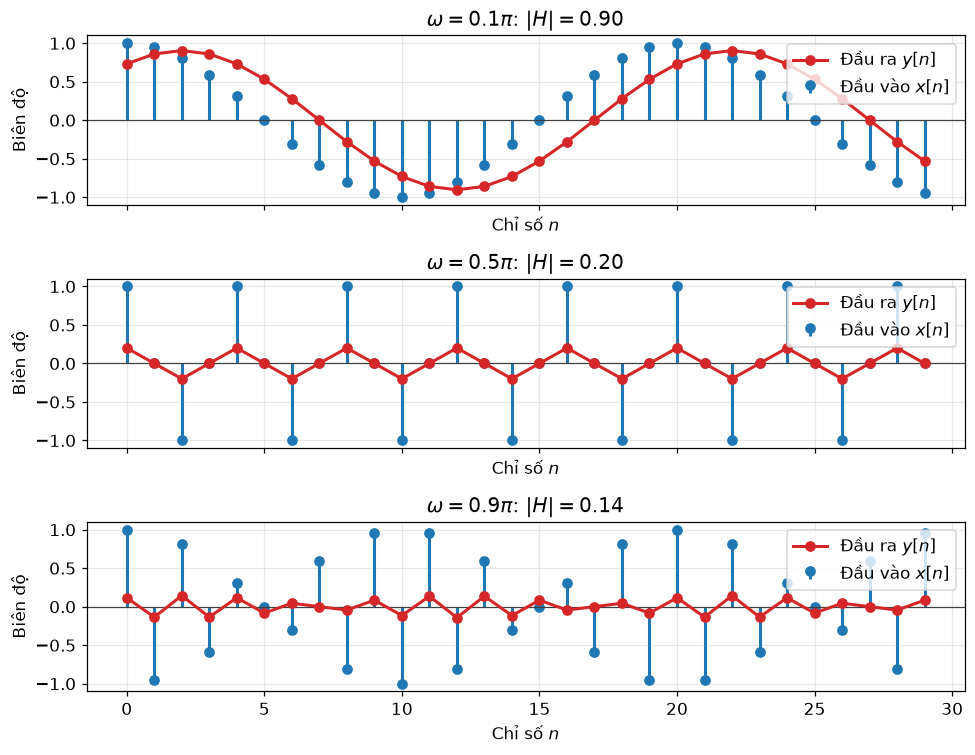

In [6]:
# Tạo ba tín hiệu hình sin thực và đầu ra trạng thái xác lập của hệ LTI.
n = np.arange(0, 30)
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)

for ax, omega_value, response in zip(axes, test_omegas, H_test):
    x_real = np.cos(omega_value * n)
    y_real = np.real(response * np.exp(1j * omega_value * n))
    stem_sequence(ax, n, x_real, label=r"Đầu vào $x[n]$", color="C0")
    ax.plot(n, y_real, "o-", color="C3", label=r"Đầu ra $y[n]$")
    ax.set_title(rf"$\omega={omega_value / np.pi:.1f}\pi$: $|H|={abs(response):.2f}$")
    ax.legend(loc="upper right")

fig.tight_layout()
plt.show()

**Nhận xét:** Bộ lọc trung bình trượt giữ tương đối tốt các thành phần gần $\omega=0$ và suy giảm các thành phần gần $\omega=\pi$. Vì thế nó có trực giác của một bộ lọc thông thấp. Tuy nhiên, đáp ứng biên độ không phải hình chữ nhật lý tưởng và đáp ứng pha cho thấy đầu ra cũng bị trễ pha.

## Câu hỏi suy ngẫm

1. Nếu giữ $f_0$ cố định nhưng tăng $f_s$, $\omega_0$ thay đổi thế nào? Dãy mẫu nhìn thay đổi ra sao?
2. Vì sao $0.1\pi$ và $1.9\pi$ đều thuộc vùng tần số thấp khi xét trong một chu kỳ $2\pi$?
3. Với bộ lọc trung bình trượt, điều gì thay đổi nếu số mẫu trung bình tăng từ năm lên chín?
4. Một hệ LTI có thể thay đổi biên độ và pha của tín hiệu hình sin. Khi nào nó chỉ tạo một trễ thuần?
5. Từ đáp ứng tần số, dự đoán điều gì xảy ra nếu đầu vào là tổng của một thành phần hình sin thấp tần và một thành phần hình sin cao tần?